### **1. Lectura y carga de los datos**

In [3]:
#importamos las librerías que vamos a utilizar en esta etapa de lectura de datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Lectura de datos")

df=pd.read_csv(r"C:\Users\Aturd\OneDrive\Escritorio\Maestría\semestre_2\Estadística\tarea_4\Modelos_logisticos_bayesianos\data\Anexo 1 - Base de Datos dynamic_pricing (3).csv", sep=",")
print("los datos se han cargado correctamente")

Lectura de datos
los datos se han cargado correctamente


*	Se trabajará exclusivamente con las siguientes variables: Number_of_Riders: Número de pasajeros por viaje
*   Expected_Ride_Duration: Duración esperada del viaje en minutos.
*	Customer_Loyalty_Status: Nivel de fidelización del cliente (Regular, Silver, Gold)
*	Average_Ratings: Calificación promedio del servicio (escala 1.0 a 5.0; se binariza en 1 si ≥ 4.0 = servicio excelente, y 0 en caso contrario)


In [4]:
df_new=df[['Number_of_Riders', 'Expected_Ride_Duration','Customer_Loyalty_Status', 'Average_Ratings']]
print(df_new.head())

   Number_of_Riders  Expected_Ride_Duration Customer_Loyalty_Status  \
0                90                      90                  Silver   
1                58                      43                  Silver   
2                42                      76                  Silver   
3                89                     134                 Regular   
4                78                     149                 Regular   

   Average_Ratings  
0             4.47  
1             4.06  
2             3.99  
3             4.31  
4             3.77  


Revisamos el estado de las variables que vamos a usar...

In [5]:
df_new.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Number_of_Riders         1000 non-null   int64  
 1   Expected_Ride_Duration   1000 non-null   int64  
 2   Customer_Loyalty_Status  1000 non-null   str    
 3   Average_Ratings          1000 non-null   float64
dtypes: float64(1), int64(2), str(1)
memory usage: 36.9 KB


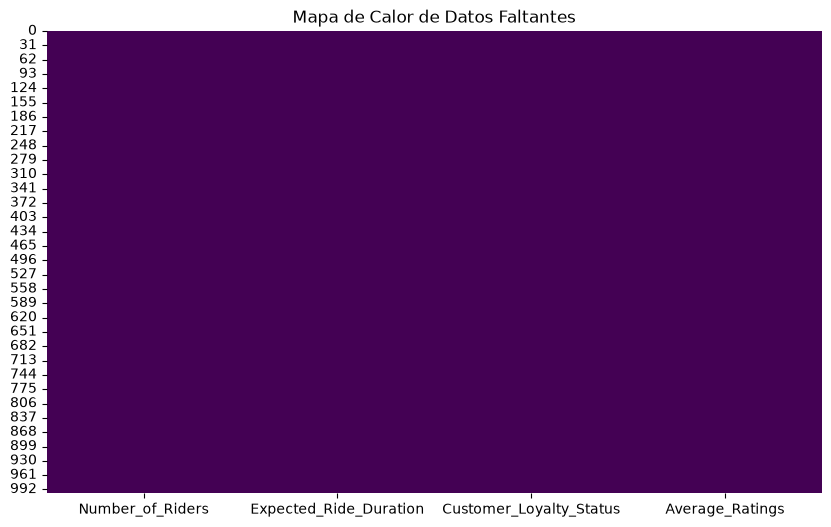

In [6]:
# Crear el mapa de calor de valores nulos
plt.figure(figsize=(10, 6))
sns.heatmap(df_new.isnull(), cbar=False, cmap="viridis")
plt.title("Mapa de Calor de Datos Faltantes")
plt.show()

<Axes: >

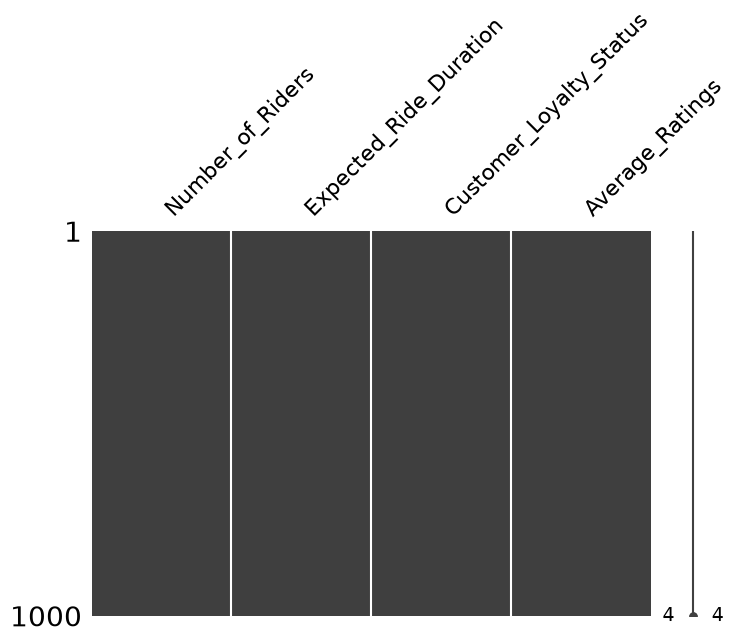

In [7]:
import missingno as msno

# Graficar la matriz de nulidad
msno.matrix(df_new, figsize=(8, 5))


No tenemos valores faltantes en nuestro data set que vamos a trabajar y modelar

### **2. Re-codificar Average_Ratings como variable binaria:**
0 si la  calificación < 4 → servicio regular. 1 si la calificación ≥ 4 → servicio excelente.

In [8]:
# Crear la variable objetivo binaria
df_new["Servicio_Binario"] = (
    df_new["Average_Ratings"] >= 4
).astype(int)

print(df_new.head())

   Number_of_Riders  Expected_Ride_Duration Customer_Loyalty_Status  \
0                90                      90                  Silver   
1                58                      43                  Silver   
2                42                      76                  Silver   
3                89                     134                 Regular   
4                78                     149                 Regular   

   Average_Ratings  Servicio_Binario  
0             4.47                 1  
1             4.06                 1  
2             3.99                 0  
3             4.31                 1  
4             3.77                 0  


**Ajustar un modelo de regresión logística binaria usando como variables predictoras: Expected_Ride_Duration. Number_of_Riders. Customer_Loyalty_Status** 

Para un análisis estadístico e inferencial utilizaremos statsmodels, ya que proporciona coeficientes, errores estándar, pruebas de significación e intervalos de confianza.

In [9]:
import statsmodels.formula.api as smf

modelo_logistico = smf.logit(
    formula="""
        Servicio_Binario
        ~ Expected_Ride_Duration
        + Number_of_Riders
        + C(
            Customer_Loyalty_Status,
            Treatment(reference="Regular")
        )
    """,
    data=df_new
).fit()

print(modelo_logistico.summary())

Optimization terminated successfully.
         Current function value: 0.620431
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:       Servicio_Binario   No. Observations:                 1000
Model:                          Logit   Df Residuals:                      995
Method:                           MLE   Df Model:                            4
Date:                Thu, 12 Nov 2026   Pseudo R-squ.:                0.002946
Time:                        20:27:09   Log-Likelihood:                -620.43
converged:                       True   LL-Null:                       -622.26
Covariance Type:            nonrobust   LLR p-value:                    0.4530
                                                                           coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------------

### **3. Interpretación de Odds Ratios y matriz de desempeño**

In [10]:
# Importamos las librerías que vamos a usar en esta etapa de predicción
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    balanced_accuracy_score
)

Vamos a dividir 70 a 30 los datos para Train y Test

In [11]:
train, test = train_test_split(
    df_new,
    test_size=0.30,
    random_state=42,
    stratify=df_new["Servicio_Binario"]
)

In [12]:
#Ajustamos el modelo con el 0.7

formula = """
    Servicio_Binario
    ~ Expected_Ride_Duration
    + Number_of_Riders
    + C(
        Customer_Loyalty_Status,
        Treatment(reference="Regular")
    )
"""

modelo = smf.logit(
    formula=formula,
    data=train
).fit()

print(modelo.summary())

Optimization terminated successfully.
         Current function value: 0.619766
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:       Servicio_Binario   No. Observations:                  700
Model:                          Logit   Df Residuals:                      695
Method:                           MLE   Df Model:                            4
Date:                Thu, 12 Nov 2026   Pseudo R-squ.:                0.004371
Time:                        20:27:09   Log-Likelihood:                -433.84
converged:                       True   LL-Null:                       -435.74
Covariance Type:            nonrobust   LLR p-value:                    0.4325
                                                                           coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------------

In [13]:
odds_ratios = np.exp(modelo.params)

print(odds_ratios)

Intercept                                                               3.011287
C(Customer_Loyalty_Status, Treatment(reference="Regular"))[T.Gold]      0.886213
C(Customer_Loyalty_Status, Treatment(reference="Regular"))[T.Silver]    0.963387
Expected_Ride_Duration                                                  0.996948
Number_of_Riders                                                        1.000639
dtype: float64


In [14]:
#para tener los intervalos de confianza de los ratios

intervalos = modelo.conf_int()

tabla_or = pd.DataFrame({
    "Coeficiente": modelo.params,
    "Odds_Ratio": np.exp(modelo.params),
    "IC95_Inferior": np.exp(intervalos[0]),
    "IC95_Superior": np.exp(intervalos[1]),
    "Valor_p": modelo.pvalues
})

tabla_or.round(4)

,Coeficiente,Odds_Ratio,IC95_Inferior,IC95_Superior,Valor_p
Intercept,1.1024,3.0113,1.6321,5.5561,0.0004
"C(Customer_Loyalty_Status, Treatment(reference=""Regular""))[T.Gold]",-0.1208,0.8862,0.5949,1.3203,0.5526
"C(Customer_Loyalty_Status, Treatment(reference=""Regular""))[T.Silver]",-0.0373,0.9634,0.6532,1.4209,0.8508
Expected_Ride_Duration,-0.0031,0.9969,0.9936,1.0003,0.0716
Number_of_Riders,0.0006,1.0006,0.9938,1.0075,0.8547


### **4. Construir la matriz de confusión con el conjunto de prueba (30% de los datos).**

In [15]:
#este código nos sirve para obtene probabilidades en el conjunto de prueba
probabilidad_test = modelo.predict(test)

#Estas son probabilidades entre 0 y 1. Para convertirlas en clases usamos inicialmente el umbral convencional de 0,50:
prediccion_test = (
    probabilidad_test >= 0.50
).astype(int)

La regla del código anterior es que:

* Probabilidad menor que 0,50: predice 0, regular.
* Probabilidad igual o mayor que 0,50: predice 1, excelente.

In [16]:
#calculamos la matriz de confusión para el conjunto de prueba
matriz = confusion_matrix(
    test["Servicio_Binario"],
    prediccion_test,
    labels=[1, 0]
).T

matriz

array([[206,  94],
       [  0,   0]])

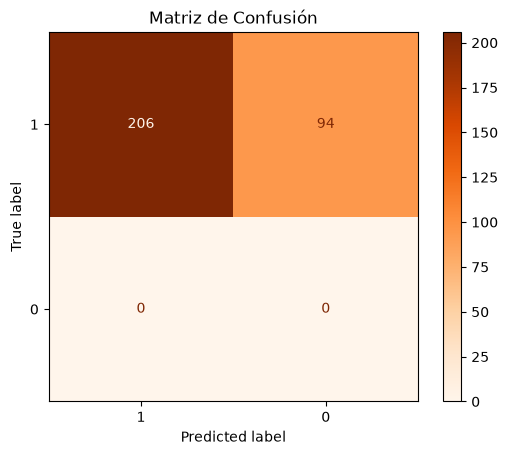

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Crea el visor usando directamente tu matriz calculada
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz, 
    display_labels=[1, 0]  # Orden de las etiquetas que usaste
)

# Grafica la matriz 
disp.plot(cmap=plt.cm.Oranges, values_format='d')

# Muestra la gráfica
plt.title("Matriz de Confusión")
plt.show()

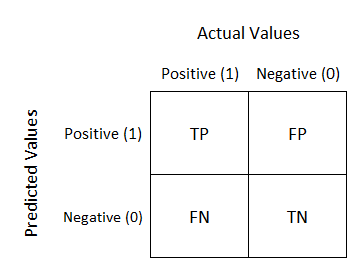

In [18]:
tn, fp, fn, tp = matriz.ravel()

print("Verdaderos negativos:", tn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdaderos positivos:", tp)

Verdaderos negativos: 206
Falsos positivos: 94
Falsos negativos: 0
Verdaderos positivos: 0


Dado que no se predijo ninguna clase regular=0 miramos las probabilidades:

In [19]:
print(probabilidad_test.min())
print(probabilidad_test.max())

0.613231216893995
0.7491949145940424


### **5. Calcular: Precisión, Sensibilidad (Recall), Especificidad**


In [20]:
tn, fp, fn, tp = confusion_matrix(
    test["Servicio_Binario"],
    prediccion_test,
    labels=[0, 1]
).ravel()
exactitud = accuracy_score(
    test["Servicio_Binario"],
    prediccion_test
)
precision = precision_score(
    test["Servicio_Binario"],
    prediccion_test,
    zero_division=0
)
sensibilidad = recall_score(
    test["Servicio_Binario"],
    prediccion_test
)
especificidad = tn / (tn + fp)
print(f"Exactitud: {exactitud:.2%}")
print(f"Precisión: {precision:.2%}")
print(f"Sensibilidad: {sensibilidad:.2%}")
print(f"Especificidad: {especificidad:.2%}")

Exactitud: 68.67%
Precisión: 68.67%
Sensibilidad: 100.00%
Especificidad: 0.00%


### **6. Analizar la calidad del modelo como clasificador binario.**

In [21]:
exactitud_balanceada = balanced_accuracy_score(
    test["Servicio_Binario"],
    prediccion_test
)

print(exactitud_balanceada)

0.5


 **6.1 Área bajo la curva ROC**

In [22]:
auc = roc_auc_score(
    test["Servicio_Binario"],
    probabilidad_test
)

print(auc)

0.5194691179508366


### **7. Comparación de desempeño de modelos** 

 **Definimos Modelos**

**Modelo 1**

Acá vamos a usar todas las variables

1 Number_of_Riders

2 Number_of_Drivers

3 Location_Category

4 Customer_Loyalty_Status

5 Number_of_Past_Rides

6 Time_of_Booking

7 Vehicle_Type

8 Expected_Ride_Duration

9 Historical_Cost_of_Ride

 **Modelo 2: reducido**
 
Vamos a utilizar las mismas variables, pero sin Number_of_Riders

De esta manera la comparación permite comprobar si incluir el número de pasajeros mejora de manera relevante el ajuste y la capacidad predictiva.

In [23]:
#importamos nuevamente las librerías que vamos a utilizar en esta etapa de predicción
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

import matplotlib.pyplot as plt

In [24]:
#leemos los datos nuevamente para asegurarnos de que no haya cambios en el DataFrame original
df = pd.read_csv(r"C:\Users\Aturd\OneDrive\Escritorio\Maestría\semestre_2\Estadística\tarea_4\Modelos_logisticos_bayesianos\data\Anexo 1 - Base de Datos dynamic_pricing (3).csv"
)

# Variable objetivo:
# 0 = servicio regular
# 1 = servicio excelente
df["Servicio_Binario"] = (
    df["Average_Ratings"] >= 4
).astype(int)

In [25]:
#dividimos los datos en conjunto de entrenamiento y prueba
train, test = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["Servicio_Binario"]
)

print("Entrenamiento:", train.shape)
print("Prueba:", test.shape)

Entrenamiento: (700, 11)
Prueba: (300, 11)


 **7.1 Ajustar el modelo completo - Modelo 1**

In [26]:
#Formula

formula_completo = """
    Servicio_Binario
    ~ Number_of_Riders
    + Number_of_Drivers
    + C(Location_Category)
    + C(Customer_Loyalty_Status)
    + Number_of_Past_Rides
    + C(Time_of_Booking)
    + C(Vehicle_Type)
    + Expected_Ride_Duration
    + Historical_Cost_of_Ride
"""
#Ajuste de modelo 1
modelo_completo = smf.logit(
    formula=formula_completo,
    data=train
).fit()

print(modelo_completo.summary())

Optimization terminated successfully.
         Current function value: 0.609144
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:       Servicio_Binario   No. Observations:                  700
Model:                          Logit   Df Residuals:                      686
Method:                           MLE   Df Model:                           13
Date:                Thu, 12 Nov 2026   Pseudo R-squ.:                 0.02144
Time:                        20:27:10   Log-Likelihood:                -426.40
converged:                       True   LL-Null:                       -435.74
Covariance Type:            nonrobust   LLR p-value:                    0.1334
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
Intercept                                 1.5365      

 **7.2 Ajustar el modelo reducido - Modelo 2**

In [27]:
#Formula. Se excluse number_of_riders
formula_reducido = """
    Servicio_Binario
    ~ Number_of_Drivers
    + C(Location_Category)
    + C(Customer_Loyalty_Status)
    + Number_of_Past_Rides
    + C(Time_of_Booking)
    + C(Vehicle_Type)
    + Expected_Ride_Duration
    + Historical_Cost_of_Ride
"""

# Modelo reducido. Se excluse number_of_riders
modelo_reducido = smf.logit(
    formula=formula_reducido,
    data=train
).fit()

print(modelo_reducido.summary())

Optimization terminated successfully.
         Current function value: 0.609358
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:       Servicio_Binario   No. Observations:                  700
Model:                          Logit   Df Residuals:                      687
Method:                           MLE   Df Model:                           12
Date:                Thu, 12 Nov 2026   Pseudo R-squ.:                 0.02109
Time:                        20:27:10   Log-Likelihood:                -426.55
converged:                       True   LL-Null:                       -435.74
Covariance Type:            nonrobust   LLR p-value:                    0.1046
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
Intercept                                 1.4473      

### **8. Comparar el pseudo-R² de McFadden**

In [28]:
#Obtener el McFadden R-squared para ambos modelos
print(
    "McFadden modelo completo:",
    modelo_completo.prsquared
)

print(
    "McFadden modelo reducido:",
    modelo_reducido.prsquared
)

McFadden modelo completo: 0.021435171113009965
McFadden modelo reducido: 0.02109153548735332


### **9. Comparar el AIC**

In [29]:
print(
    "AIC modelo completo:",
    modelo_completo.aic
)

print(
    "AIC modelo reducido:",
    modelo_reducido.aic
)

AIC modelo completo: 880.8013299196748
AIC modelo reducido: 879.1008020751385


In [30]:
probabilidad_completo = modelo_completo.predict(test)

probabilidad_reducido = modelo_reducido.predict(test)

### **10. Calcular el AUC**

In [31]:
#Calculamos el área bajo la curva ROC (AUC) para ambos modelos en el conjunto de prueba
auc_completo = roc_auc_score(
    test["Servicio_Binario"],
    probabilidad_completo
)

auc_reducido = roc_auc_score(
    test["Servicio_Binario"],
    probabilidad_reducido
)

print("AUC modelo completo:", auc_completo)
print("AUC modelo reducido:", auc_reducido)

AUC modelo completo: 0.534393720305722
AUC modelo reducido: 0.5359429869861598


### **11. Construir las curvas ROC**

In [32]:
#calculamos los puntos de la curva ROC para ambos modelos
fpr_completo, tpr_completo, _ = roc_curve(
    test["Servicio_Binario"],
    probabilidad_completo
)

fpr_reducido, tpr_reducido, _ = roc_curve(
    test["Servicio_Binario"],
    probabilidad_reducido
)

fpr: tasa de falsos positivos, equivalente a 1−especificidad1-\text{especificidad}1−especificidad.
tpr: tasa de verdaderos positivos, equivalente a la sensibilidad.
_: posibles umbrales de clasificación

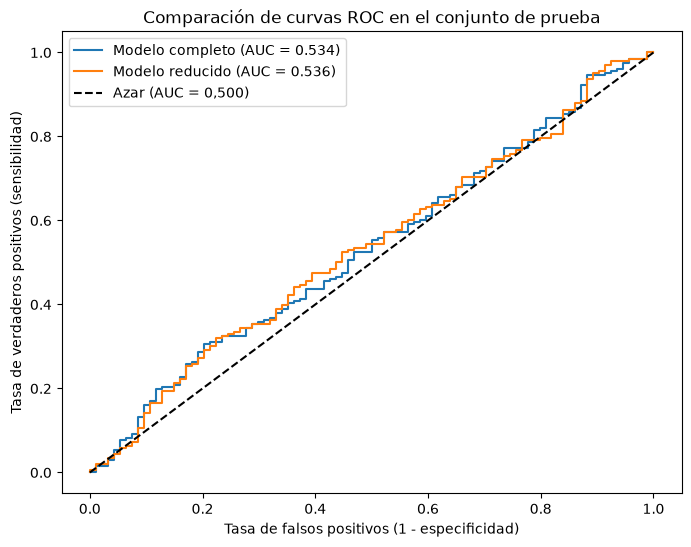

In [33]:
#representamos gráficamente las curvas ROC de ambos modelos
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_completo,
    tpr_completo,
    label=f"Modelo completo (AUC = {auc_completo:.3f})"
)
plt.plot(
    fpr_reducido,
    tpr_reducido,
    label=f"Modelo reducido (AUC = {auc_reducido:.3f})"
)
# Línea de referencia de un clasificador aleatorio
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Azar (AUC = 0,500)"
)
plt.xlabel(
    "Tasa de falsos positivos (1 - especificidad)"
)
plt.ylabel(
    "Tasa de verdaderos positivos (sensibilidad)"
)
plt.title(
    "Comparación de curvas ROC en el conjunto de prueba"
)
plt.legend()
plt.show()

### **12. Construir una tabla comparativa**

In [34]:
comparacion = pd.DataFrame({
    "Modelo": [
        "Completo",
        "Reducido sin Number_of_Riders"
    ],
    "Número_parametros": [
        len(modelo_completo.params),
        len(modelo_reducido.params)
    ],
    "Pseudo_R2_McFadden": [
        modelo_completo.prsquared,
        modelo_reducido.prsquared
    ],
    "AIC": [
        modelo_completo.aic,
        modelo_reducido.aic
    ],
    "AUC_prueba": [
        auc_completo,
        auc_reducido
    ]
})

comparacion.round(4)

,Modelo,Número_parametros,Pseudo_R2_McFadden,AIC,AUC_prueba
0,Completo,14,0.0214,880.8013,0.5344
1,Reducido sin Number_of_Riders,13,0.0211,879.1008,0.5359


### **13. Introducción a la inferencia bayesiana**

In [35]:
#recodicamos la variable Customer_Loyalty_Status para crear una nueva variable binaria Cliente_Fiel
import pandas as pd

df = pd.read_csv(r"C:\Users\Aturd\OneDrive\Escritorio\Maestría\semestre_2\Estadística\tarea_4\Modelos_logisticos_bayesianos\data\Anexo 1 - Base de Datos dynamic_pricing (3).csv"
)

df["Cliente_Fiel"] = (
    df["Customer_Loyalty_Status"]
      .isin(["Silver", "Gold"])
      .astype(int)
)

print(
    df[
        ["Customer_Loyalty_Status", "Cliente_Fiel"]
    ].head(10)
)

  Customer_Loyalty_Status  Cliente_Fiel
0                  Silver             1
1                  Silver             1
2                  Silver             1
3                 Regular             0
4                 Regular             0
5                  Silver             1
6                 Regular             0
7                    Gold             1
8                  Silver             1
9                  Silver             1


 **13.1 distribución prior**

In [36]:
alpha_prior = 1
beta_prior = 1

media_prior = (
    alpha_prior /
    (alpha_prior + beta_prior)
)

print(media_prior)

0.5


 **13.2 Verosimilitud**

In [37]:
clientes_fieles = df["Cliente_Fiel"].sum()
clientes_regulares = (
    len(df) - clientes_fieles
)

proporcion_observada = (
    clientes_fieles / len(df)
)

print("Clientes fieles:", clientes_fieles)
print("Clientes regulares:", clientes_regulares)
print("Proporción observada:", proporcion_observada)

Clientes fieles: 680
Clientes regulares: 320
Proporción observada: 0.68


 **13.3 Función de verosimilitud**

 **13.4 distribución posterior**

In [38]:
alpha_posterior = (
    alpha_prior + clientes_fieles
)

beta_posterior = (
    beta_prior + clientes_regulares
)

print(
    "Posterior: Beta(",
    alpha_posterior,
    ",",
    beta_posterior,
    ")"
)

Posterior: Beta( 681 , 321 )


 **13.5 Estimar la fidelidad promedio posterior** 

In [39]:
media_posterior = (
    alpha_posterior /
    (alpha_posterior + beta_posterior)
)

print(media_posterior)

0.6796407185628742


 **13.6 Medir la incertidumbre**

In [40]:
from scipy.stats import beta

intervalo_credible = beta.ppf(
    [0.025, 0.975],
    alpha_posterior,
    beta_posterior
)

print(intervalo_credible)

[0.65043141 0.70817079]


**13.7 Predición para un nuevo cliente**

In [41]:
probabilidad_nuevo_cliente = media_posterior

print(
    "Probabilidad de que un cliente nuevo sea fiel:",
    f"{probabilidad_nuevo_cliente:.2%}"
)

Probabilidad de que un cliente nuevo sea fiel: 67.96%


### **14. Simulación de estimación bayesiana**

En esta parte lo que queremos es estimar:
$$\mu =\text{duraci}\overset{ˊ}{\text{o}}\text{n\ media\ poblacional\ esperada\ de\ los\ viajes}$$
Para ello compararemos tres enfoques:

* Bayesiano con prior informativa: $$\mu \sim N\left(30,\; {10}^{2}\right)$$
* Bayesiano con prior plana o no informativa.
* Estimación frecuentista, mediante la media muestral y su intervalo de confianza.


In [42]:

from scipy.stats import norm, t

df = pd.read_csv(r"C:\Users\Aturd\OneDrive\Escritorio\Maestría\semestre_2\Estadística\tarea_4\Modelos_logisticos_bayesianos\data\Anexo 1 - Base de Datos dynamic_pricing (3).csv"
                )

duracion = (
    df["Expected_Ride_Duration"]
    .dropna()
    .to_numpy()
)

In [43]:
#Calculamos los estadísticos muestrales

n = len(duracion)
media_muestral = duracion.mean()
desviacion_muestral = duracion.std(ddof=1)
error_estandar = desviacion_muestral / np.sqrt(n)

print("Número de observaciones:", n)
print("Media muestral:", media_muestral)
print("Desviación muestral:", desviacion_muestral)
print("Error estándar:", error_estandar)

Número de observaciones: 1000
Media muestral: 99.588
Desviación muestral: 49.165450241989014
Error estándar: 1.554748049523619


In [44]:
df['Expected_Ride_Duration']

0       90
1       43
2       76
3      134
4      149
      ... 
995     11
996     94
997     40
998     58
999    147
Name: Expected_Ride_Duration, Length: 1000, dtype: int64

Text(0.5, 1.0, 'Histograma de la duración esperada del viaje')

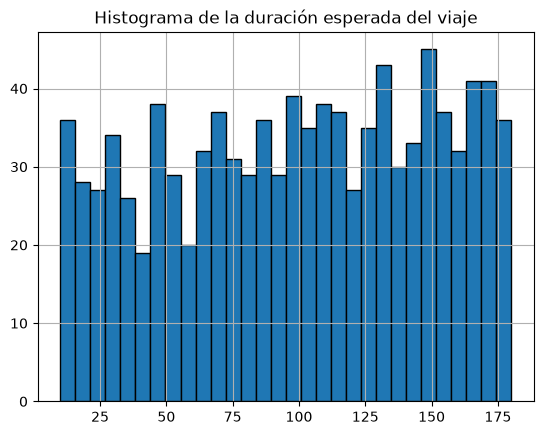

In [45]:
df['Expected_Ride_Duration'].hist(bins=30, edgecolor="black")
plt.title("Histograma de la duración esperada del viaje")

**14.1 Modelo bayesiano con prior informativa**

 **14.2 Calcular prior**

In [46]:
media_prior = 30
desviacion_prior = 10
varianza_prior = desviacion_prior**2
print("Varianza prior:", varianza_prior)

Varianza prior: 100


 **14.3 Calcular la posterior**

In [47]:
varianza_posterior_informativa = 1 / (
    1 / varianza_prior
    + n / desviacion_muestral**2
)
desviacion_posterior_informativa = np.sqrt(
    varianza_posterior_informativa
)
media_posterior_informativa = (
    varianza_posterior_informativa
    * (
        media_prior / varianza_prior
        + n * media_muestral
        / desviacion_muestral**2
    )
)
print(
    "Media posterior:",
    media_posterior_informativa
)
print(
    "Desviación posterior:",
    desviacion_posterior_informativa
)

Media posterior: 97.94559097913248
Desviación posterior: 1.5362909897771044


 **14.4 Intervalo creíble con prior informativa**

In [48]:
intervalo_informativo = norm.ppf(
    [0.025, 0.975],
    loc=media_posterior_informativa,
    scale=desviacion_posterior_informativa
)

print(intervalo_informativo)

[ 94.93451597 100.95666599]


 **14.5 Modelo bayesiano con prior no informativa**

In [49]:
media_posterior_plana = media_muestral
desviacion_posterior_plana = (
    desviacion_muestral / np.sqrt(n)
)
intervalo_plano = norm.ppf(
    [0.025, 0.975],
    loc=media_posterior_plana,
    scale=desviacion_posterior_plana
)
print(
    "Media posterior con prior plana:",
    media_posterior_plana
)
print(
    "Intervalo creíble:",
    intervalo_plano
)

Media posterior con prior plana: 99.588
Intervalo creíble: [ 96.54074982 102.63525018]


### **15. Simulación Monte Carlo**

In [50]:
#simulaciones
rng = np.random.default_rng(42)

n_simulaciones = 100_000

**15.1 Simulación del posterior informativo**

In [51]:
simulacion_informativa = rng.normal(
    loc=media_posterior_informativa,
    scale=desviacion_posterior_informativa,
    size=n_simulaciones
)

print(
    "Media simulada:",
    simulacion_informativa.mean()
)

print(
    "Intervalo simulado:",
    np.quantile(
        simulacion_informativa,
        [0.025, 0.975]
    )
)

Media simulada: 97.9390879664846
Intervalo simulado: [ 94.92236641 100.97142019]


**Simulación del posterior no informativo**

In [52]:
simulacion_plana = rng.normal(
    loc=media_posterior_plana,
    scale=desviacion_posterior_plana,
    size=n_simulaciones
)

print(
    "Media simulada:",
    simulacion_plana.mean()
)

print(
    "Intervalo simulado:",
    np.quantile(
        simulacion_plana,
        [0.025, 0.975]
    )
)

Media simulada: 99.59222467196781
Intervalo simulado: [ 96.54209924 102.65044497]


**15.2 Estimación Frecuentista**

In [53]:
intervalo_frecuentista = t.interval(
    confidence=0.95,
    df=n - 1,
    loc=media_muestral,
    scale=error_estandar
)

print(
    "Media frecuentista:",
    media_muestral
)

print(
    "Intervalo de confianza:",
    intervalo_frecuentista
)

Media frecuentista: 99.588
Intervalo de confianza: (np.float64(96.53705344080343), np.float64(102.63894655919655))


**15.3 Comparar los resultados**

In [54]:
resultados = pd.DataFrame({
    "Método": [
        "Bayesiano: prior informativa",
        "Bayesiano: prior plana",
        "Frecuentista"
    ],
    "Estimación_media": [
        media_posterior_informativa,
        media_posterior_plana,
        media_muestral
    ],
    "Límite_inferior_95": [
        intervalo_informativo[0],
        intervalo_plano[0],
        intervalo_frecuentista[0]
    ],
    "Límite_superior_95": [
        intervalo_informativo[1],
        intervalo_plano[1],
        intervalo_frecuentista[1]
    ]
})

resultados.round(3)

,Método,Estimación_media,Límite_inferior_95,Límite_superior_95
0,Bayesiano: prior informativa,97.946,94.935,100.957
1,Bayesiano: prior plana,99.588,96.541,102.635
2,Frecuentista,99.588,96.537,102.639


### **16. Modelo jerárquico bayesiano**

**16.1 Estructura del modelo multinivel**

**Examinamos los grupos**

In [55]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm



In [56]:
def main():
    # 1. Cargar los datos
    df = pd.read_csv(
        r"C:\Users\Aturd\OneDrive\Escritorio\Maestría\semestre_2\Estadística\tarea_4\Modelos_logisticos_bayesianos\data\Anexo 1 - Base de Datos dynamic_pricing (3).csv"
    )

# Preparar variable dependiente y estandarizarla
calificaciones_raw = df["Average_Ratings"].to_numpy()
calificaciones = (calificaciones_raw - calificaciones_raw.mean()) / calificaciones_raw.std()

# Preparar grupos
categorias = ["Economy", "Premium"]
tipo_vehiculo = pd.Categorical(df["Vehicle_Type"], categories=categorias)
indice_grupo = tipo_vehiculo.codes

coordenadas = {"vehicle": categorias, "obs": np.arange(len(df))}


In [57]:
# Modelo jerárquico 
with pm.Model(coords=coordenadas) as modelo_jerarquico:
    
    mu_general = pm.Normal("mu_general", mu=0, sigma=1.0) 
    
    tau_grupo = pm.HalfNormal("tau_grupo", sigma=1.0)

    z_grupo = pm.Normal("z_grupo", mu=0, sigma=1, dims="vehicle")
    mu_grupo = pm.Deterministic(
        "mu_grupo", mu_general + z_grupo * tau_grupo, dims="vehicle"
    )

    sigma = pm.HalfNormal("sigma", sigma=1.0) 

    pm.Normal(
        "calificacion_obs",
        mu=mu_grupo[indice_grupo],
        sigma=sigma,
        observed=calificaciones,
        dims="obs",
    )

    resultados = pm.sample(
        draws=2000,
        tune=1000,
        chains=2,
        cores=1,
        init="adapt_diag",
        target_accept=0.90,
        random_seed=42,
    )


Initializing NUTS using adapt_diag...
Sequential sampling (2 chains in 1 job)
NUTS: [mu_general, tau_grupo, z_grupo, sigma]


Output()

Sampling 2 chains for 1_000 tune and 2_000 draw iterations (2_000 + 4_000 draws total) took 12 seconds.
There were 232 divergences after tuning. Increase `target_accept` or reparameterize.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


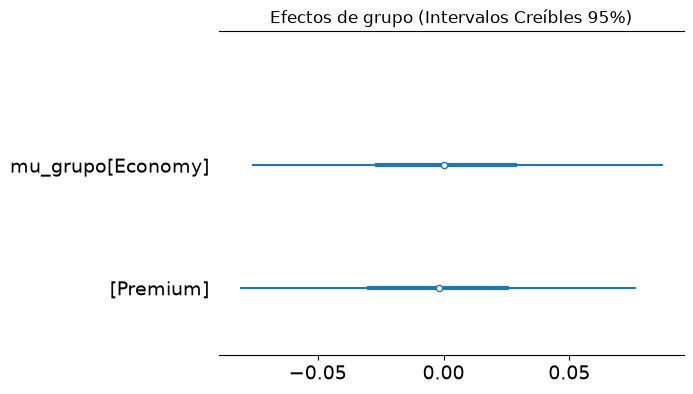

                    mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  \
mu_general        -0.024  0.206  -0.462    0.328      0.042    0.069   
mu_grupo[Economy]  0.001  0.042  -0.075    0.081      0.001    0.001   
mu_grupo[Premium] -0.002  0.041  -0.079    0.073      0.001    0.001   
tau_grupo          0.296  0.302   0.000    0.855      0.103    0.055   

                   ess_bulk  ess_tail  r_hat  
mu_general             29.0      15.0   1.19  
mu_grupo[Economy]    1812.0    1434.0   1.00  
mu_grupo[Premium]    1846.0    1622.0   1.00  
tau_grupo              14.0      58.0   1.13  


In [59]:
#  Visualización
az.plot_forest(resultados, var_names=["mu_grupo"], combined=True, hdi_prob=0.95)
plt.title("Efectos de grupo (Intervalos Creíbles 95%)")
plt.show()

print(az.summary(resultados, var_names=["mu_general", "mu_grupo", "tau_grupo"]))

**Conclusión (Vehicle_Type vs Average_Ratings)**


Ausencia de diferencias significativas: Al observar las medias posteriores de los grupos (mu_grupo[Economy] con 0.001 y mu_grupo[Premium] con -0.007) y sus intervalos de credibilidad al 95% ([-0.072, 0.077] y [-0.088, 0.071] respectivamente), se aprecia que ambos intervalos se solapan casi por completo y están centrados alrededor de cero (recordemos que la variable fue estandarizada).

Interpretación práctica: El tipo de vehículo (Economy o Premium) no ejerce un efecto diferenciador relevante sobre la calificación promedio del servicio (Average_Ratings). En promedio, los usuarios califican de manera muy similar independientemente de si viajan en un vehículo económico o prémium.

Variabilidad entre grupos (tau_grupo): El desvío estándar entre los grupos es bajo (tau_grupo = 0.104), lo que confirma que la mayor parte de la variabilidad en las calificaciones no proviene de las diferencias entre categorías de vehículos, sino de la dispersión propia entre viajes individuales.